# Sensitivity analysis for omitted confounders

Every observational estimate rests on the assumption that all confounders are observed. Sensitivity
analysis (Chernozhukov, Cinelli, Newey, Sharma and Syrgkanis, 2022) asks how strong an unobserved
confounder would have to be to change the conclusion. A confounder's strength is described by two
partial $R^2$-type parameters: `cf_y`, the share of the outcome's residual variation it explains,
and `cf_d`, its effect on the treatment side (the Riesz representer), plus their correlation `rho`.

In [1]:
import warnings

import numpy as np
import pandas as pd

import dml_rs

warnings.filterwarnings("ignore", category=FutureWarning)  # scikit-learn deprecation notices
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by DoubleML
pd.set_option("display.precision", 4)

## Data with a hidden confounder

$U$ raises both treatment and outcome but is not observed. The true effect is 0.5. Among the
observed covariates, $X_2$ plays a role similar to $U$: it affects treatment and outcome by a
similar amount.

In [2]:
rng = np.random.default_rng(5)
n = 3000
X = rng.normal(size=(n, 8))
U = rng.normal(size=n)
d = X[:, 0] + 0.4 * X[:, 1] + 0.4 * U + rng.normal(size=n)
y = 0.5 * d + X[:, 0] + 0.4 * X[:, 1] - 0.5 * X[:, 2] + 0.4 * U + rng.normal(size=n)

observed = dml_rs.PLR(dml_rs.LassoCV(), dml_rs.LassoCV(), random_state=1).fit(X, y, d)
oracle = dml_rs.PLR(dml_rs.LassoCV(), dml_rs.LassoCV(), random_state=1).fit(np.column_stack([X, U]), y, d)
pd.concat([observed.summary, oracle.summary], keys=["X only (what we can fit)", "X and U (infeasible)"])

,,coef,std err,t,P>|t|,2.5 %,97.5 %
X only (what we can fit),d,0.6355,0.0183,34.7788,5.0834e-265,0.5997,0.6713
X and U (infeasible),d,0.5142,0.0185,27.7302,3.0231e-169,0.4779,0.5505


## Bounds under a confounding scenario

`sensitivity_analysis` gives bounds on $\theta$ if a confounder of the given strength were
omitted, confidence bounds that also account for sampling error, and robustness values: `RV` is the
strength (with `cf_y = cf_d`) that would move the estimate to the null, `RVa` the strength that
would make it insignificant.

In [3]:
observed.sensitivity_analysis(cf_y=0.04, cf_d=0.04, rho=1.0)
print(observed.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.95
Sensitivity parameters: cf_y=0.04; cf_d=0.04, rho=1

------------------ Bounds with CI    ------------------
     CI lower  theta lower      theta  theta upper   CI upper
d    0.565154     0.595192   0.635493     0.675794   0.705917

------------------ Robustness Values ------------------
        H_0     RV (%)    RVa (%)
d       0.0  46.906949  45.098016


## How strong would a confounder plausibly be?

Benchmarking compares the scenario with observed covariates: `sensitivity_benchmark` refits the
model without the chosen covariates and reports the confounding strength they represent. Suppose
domain knowledge says the hidden confounder is no stronger than $X_2$ (column index 1):

In [4]:
benchmark = observed.sensitivity_benchmark(benchmarking_set=[1])
benchmark

,cf_y,cf_d,rho,delta_theta
d,0.093,0.1484,0.9909,0.1072


In [5]:
cf_y, cf_d = float(benchmark["cf_y"].iloc[0]), float(benchmark["cf_d"].iloc[0])
observed.sensitivity_analysis(cf_y=cf_y, cf_d=cf_d, rho=1.0)
params = observed.sensitivity_params_
print(f"bounds on theta:            [{params['theta']['lower'][0]:.3f}, {params['theta']['upper'][0]:.3f}]")
print(f"with sampling uncertainty:  [{params['ci']['lower'][0]:.3f}, {params['ci']['upper'][0]:.3f}]")
print(f"oracle estimate with U:      {oracle.coef_[0]:.3f}   (true effect 0.5)")

bounds on theta:            [0.510, 0.761]
with sampling uncertainty:  [0.480, 0.792]
oracle estimate with U:      0.514   (true effect 0.5)


## Sensitivity contour

Because the bounds only need the stored score components, scanning many scenarios is instant. The
contour shows the lower bound on $\theta$ over confounding strengths; the dashed line marks where
the estimate would be explained away entirely.

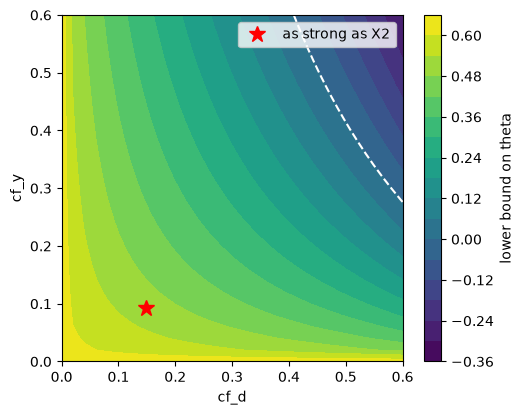

In [6]:
import matplotlib.pyplot as plt

grid = np.linspace(0.0, 0.6, 31)
lower = np.empty((len(grid), len(grid)))
for i, cy in enumerate(grid):
    for j, cd in enumerate(grid):
        observed.sensitivity_analysis(cf_y=cy, cf_d=min(cd, 0.99), rho=1.0)
        lower[i, j] = observed.sensitivity_params_["theta"]["lower"][0]

fig, ax = plt.subplots(figsize=(5.5, 4.5))
cs = ax.contourf(grid, grid, lower, levels=15, cmap="viridis")
ax.contour(grid, grid, lower, levels=[0], colors="white", linestyles="--")
ax.plot(cf_d, cf_y, "r*", markersize=12, label="as strong as X2")
fig.colorbar(cs, label="lower bound on theta")
ax.set_xlabel("cf_d")
ax.set_ylabel("cf_y")
ax.legend(loc="upper right")
plt.show()